In [47]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
from scipy import stats

# ============================================================================
# LOAD DATA AND TRAIN MODEL
# ============================================================================
print("="*80)
print("LOADING DATA")
print("="*80)

# Load in-sample data and train model
df_ins = pd.read_csv("Final_InSample_Frozen.csv", index_col=0, parse_dates=True)
print(f"In-sample data shape: {df_ins.shape}")
print(f"In-sample columns: {df_ins.columns.tolist()}")

# Prepare in-sample data
y_ins = df_ins['cl1_ret']
X_ins = df_ins.drop(columns=['cl1_ret'])

# Train model
print("\nTraining OLS model on in-sample data...")
model_final = sm.OLS(y_ins, X_ins).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
print(model_final.summary())

# Load out-of-sample data
print("\n" + "="*80)
print("LOADING OUT-OF-SAMPLE DATA")
print("="*80)

df_oos = pd.read_csv("Final_OutOfSample_Frozen.csv", index_col=0, parse_dates=True)
print(f"Out-of-sample data shape: {df_oos.shape}")
print(f"Out-of-sample columns: {df_oos.columns.tolist()}")

# Check column alignment
print("\n" + "="*80)
print("CHECKING COLUMN ALIGNMENT")
print("="*80)

ins_cols = df_ins.columns.tolist()
oos_cols = df_oos.columns.tolist()

print(f"\nIn-sample columns: {ins_cols}")
print(f"Out-of-sample columns: {oos_cols}")
print(f"Columns match: {set(ins_cols) == set(oos_cols)}")

LOADING DATA
In-sample data shape: (1195, 9)
In-sample columns: ['cl1_ret', 'const', 'dow_jones_us_oilandgas_index_ret', 'exxonmobil_ret', 'cl1_ret_l2', 'weekly_commercial_short_diff', 'weekly_commercial_long_diff', 'weekly_change_in_crude_stock_diff', 'cl1_ret_l2_squared']

Training OLS model on in-sample data...
                            OLS Regression Results                            
Dep. Variable:                cl1_ret   R-squared:                       0.051
Model:                            OLS   Adj. R-squared:                  0.045
Method:                 Least Squares   F-statistic:                     8.519
Date:                Mon, 17 Nov 2025   Prob (F-statistic):           3.29e-10
Time:                        22:15:14   Log-Likelihood:                 1907.4
No. Observations:                1195   AIC:                            -3799.
Df Residuals:                    1187   BIC:                            -3758.
Df Model:                           7               

In [48]:
# ============================================================================
# OUT-OF-SAMPLE TESTING
# ============================================================================
print("\n" + "="*80)
print("OUT-OF-SAMPLE MODEL TESTING")
print("="*80)

# Extract target variable from OOS data
y_oos = df_oos['cl1_ret'].copy()
print(f"\nExtracted y_oos with shape: {y_oos.shape}")

# Get features from OOS data using same features as training
model_features = X_ins.columns.tolist()
X_oos = df_oos[model_features].copy()
print(f"X_oos shape: {X_oos.shape}")
print(f"X_oos columns match training: {X_oos.columns.tolist() == model_features}")

# Make predictions
print("\nMaking predictions on out-of-sample data...")
y_oos_pred = model_final.predict(X_oos)
print(f"Predictions shape: {y_oos_pred.shape}")

# Calculate performance metrics
mse_oos = mean_squared_error(y_oos, y_oos_pred)
rmse_oos = np.sqrt(mse_oos)
mae_oos = mean_absolute_error(y_oos, y_oos_pred)
r2_oos = r2_score(y_oos, y_oos_pred)

# Calculate residuals
residuals_oos = y_oos - y_oos_pred

print("\n" + "="*80)
print("OUT-OF-SAMPLE PERFORMANCE METRICS")
print("="*80)
print(f"Mean Squared Error (MSE):        {mse_oos:.6f}")
print(f"Root Mean Squared Error (RMSE):  {rmse_oos:.6f}")
print(f"Mean Absolute Error (MAE):       {mae_oos:.6f}")
print(f"R² Score:                        {r2_oos:.6f}")
print(f"Mean Residual:                   {residuals_oos.mean():.6f}")
print(f"Std Dev of Residuals:            {residuals_oos.std():.6f}")

# Residual statistics
print("\nRESIDUAL STATISTICS")
print("-" * 80)
print(f"Min Residual:                    {residuals_oos.min():.6f}")
print(f"Max Residual:                    {residuals_oos.max():.6f}")
print(f"Median Residual:                 {residuals_oos.median():.6f}")
print(f"Skewness:                        {residuals_oos.skew():.6f}")
print(f"Kurtosis:                        {residuals_oos.kurtosis():.6f}")

# Directional accuracy
correct_direction = ((y_oos > 0) == (y_oos_pred > 0)).sum()
directional_accuracy = correct_direction / len(y_oos) * 100
print(f"\nDirectional Accuracy:            {directional_accuracy:.2f}%")


OUT-OF-SAMPLE MODEL TESTING

Extracted y_oos with shape: (339,)
X_oos shape: (339, 8)
X_oos columns match training: True

Making predictions on out-of-sample data...
Predictions shape: (339,)

OUT-OF-SAMPLE PERFORMANCE METRICS
Mean Squared Error (MSE):        0.003931
Root Mean Squared Error (RMSE):  0.062698
Mean Absolute Error (MAE):       0.042914
R² Score:                        -0.033208
Mean Residual:                   0.001271
Std Dev of Residuals:            0.062778

RESIDUAL STATISTICS
--------------------------------------------------------------------------------
Min Residual:                    -0.376633
Max Residual:                    0.336047
Median Residual:                 0.005348
Skewness:                        -0.279475
Kurtosis:                        7.225606

Directional Accuracy:            55.75%


In [49]:
# ============================================================================
# IN-SAMPLE vs OUT-OF-SAMPLE COMPARISON
# ============================================================================
print("\n" + "="*80)
print("IN-SAMPLE vs OUT-OF-SAMPLE COMPARISON")
print("="*80)

y_ins_pred = model_final.fittedvalues
r2_ins = model_final.rsquared
mse_ins = mean_squared_error(y_ins, y_ins_pred)
rmse_ins = np.sqrt(mse_ins)
mae_ins = mean_absolute_error(y_ins, y_ins_pred)

comparison_df = pd.DataFrame({
    'Metric': ['R² Score', 'MSE', 'RMSE', 'MAE'],
    'In-Sample': [f"{r2_ins:.6f}", f"{mse_ins:.6f}", f"{rmse_ins:.6f}", f"{mae_ins:.6f}"],
    'Out-of-Sample': [f"{r2_oos:.6f}", f"{mse_oos:.6f}", f"{rmse_oos:.6f}", f"{mae_oos:.6f}"]
})

print("\n" + comparison_df.to_string(index=False))


IN-SAMPLE vs OUT-OF-SAMPLE COMPARISON

  Metric In-Sample Out-of-Sample
R² Score  0.050537     -0.033208
     MSE  0.002405      0.003931
    RMSE  0.049042      0.062698
     MAE  0.036093      0.042914



CREATING VISUALIZATIONS
Visualization saved as 'OOS_Model_Performance.png'


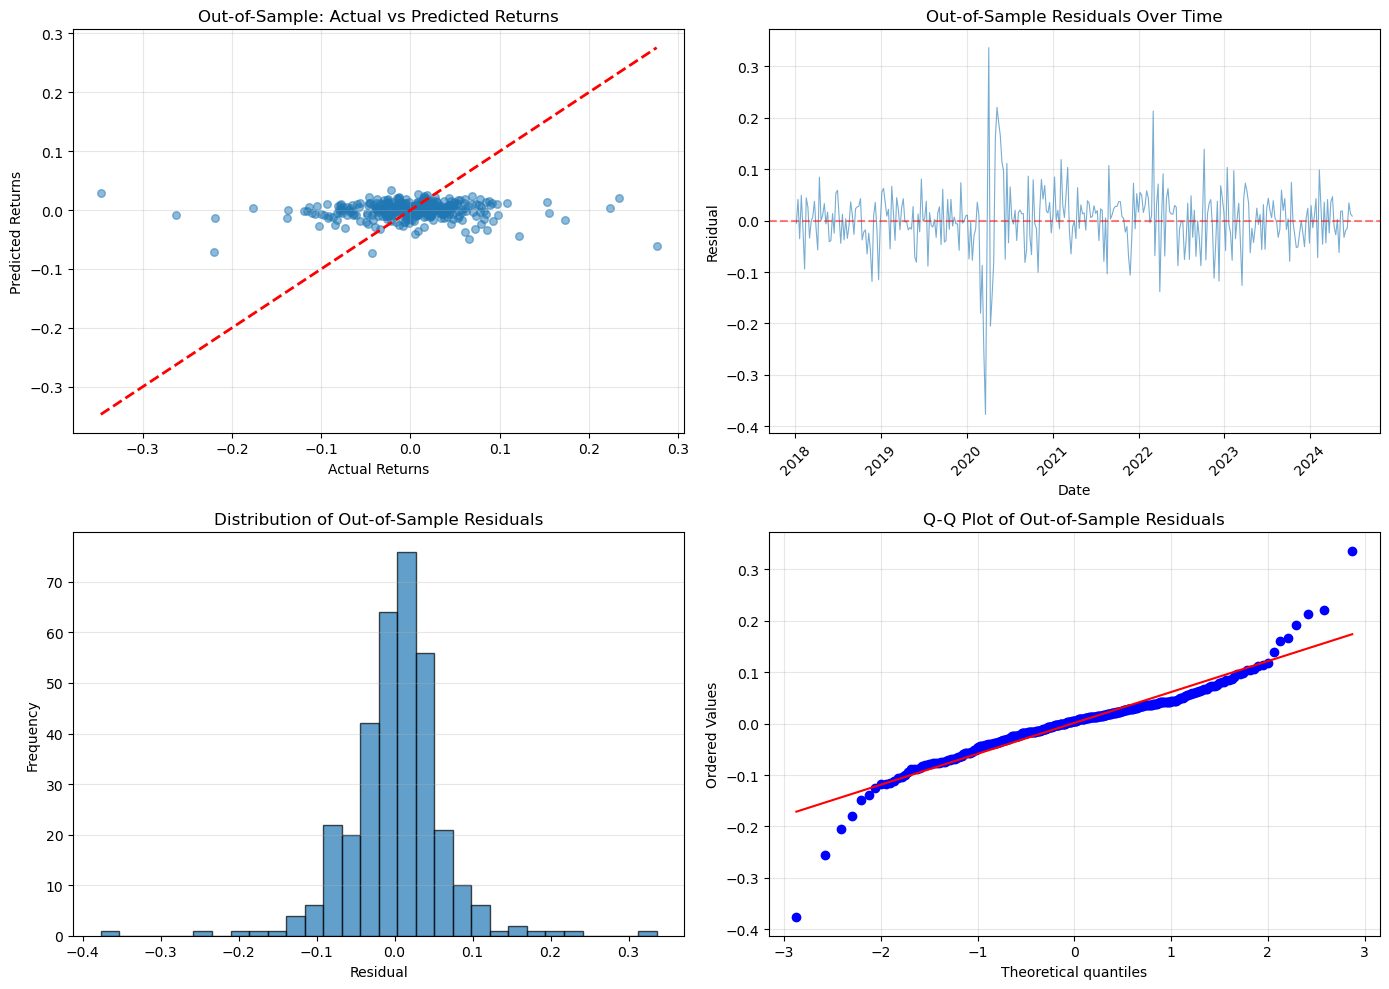


OUT-OF-SAMPLE TESTING COMPLETE


In [50]:
# ============================================================================
# VISUALIZATIONS
# ============================================================================
print("\n" + "="*80)
print("CREATING VISUALIZATIONS")
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Actual vs Predicted
axes[0, 0].scatter(y_oos, y_oos_pred, alpha=0.5, s=30)
axes[0, 0].plot([y_oos.min(), y_oos.max()], [y_oos.min(), y_oos.max()], 'r--', lw=2)
axes[0, 0].set_xlabel('Actual Returns')
axes[0, 0].set_ylabel('Predicted Returns')
axes[0, 0].set_title('Out-of-Sample: Actual vs Predicted Returns')
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Residuals over time
axes[0, 1].plot(residuals_oos.index, residuals_oos.values, alpha=0.6, linewidth=0.8)
axes[0, 1].axhline(y=0, color='r', linestyle='--', alpha=0.5)
axes[0, 1].set_xlabel('Date')
axes[0, 1].set_ylabel('Residual')
axes[0, 1].set_title('Out-of-Sample Residuals Over Time')
axes[0, 1].grid(True, alpha=0.3)
plt.setp(axes[0, 1].xaxis.get_majorticklabels(), rotation=45)

# Plot 3: Residuals histogram
axes[1, 0].hist(residuals_oos, bins=30, edgecolor='black', alpha=0.7)
axes[1, 0].set_xlabel('Residual')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Distribution of Out-of-Sample Residuals')
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Plot 4: Q-Q plot
stats.probplot(residuals_oos, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot of Out-of-Sample Residuals')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('OOS_Model_Performance.png', dpi=300, bbox_inches='tight')
print("Visualization saved as 'OOS_Model_Performance.png'")
plt.show()

print("\n" + "="*80)
print("OUT-OF-SAMPLE TESTING COMPLETE")
print("="*80)
